# RNN / LSTM / GRU — analiza sentymentu tweetów

**Cel:** zbudować działający klasyfikator tekstu, porównać trzy architektury rekurencyjne i przygotować punkt wyjścia do optymalizacji przez kursantów.

Notebook jest **samowystarczalny**:
- korzysta z pliku `twitter_sentiment_sample.csv`, jeśli znajduje się obok notebooka,
- jeśli pliku nie ma, tworzy mały syntetyczny zbiór demonstracyjny,
- działa bez pobierania danych z internetu,
- zawiera trening, walidację, test, wykresy, macierz pomyłek i predykcję własnych zdań.

> **Pełny rzeczywisty zbiór Sentiment140:** https://www.kaggle.com/datasets/kazanova/sentiment140  
> W Sentiment140 etykiety to zwykle `0 = negative` i `4 = positive`. W tym notebooku używamy `0/1`.

### Zadanie dla kursanta
Uruchom wersję bazową, a następnie popraw wynik przez zmianę m.in.:
1. `MAX_VOCAB`, `MAX_LEN`,
2. `EMBED_DIM`, `HIDDEN_DIM`,
3. liczby warstw i `dropout`,
4. `learning_rate`, `batch_size`, liczby epok,
5. typu warstwy: `RNN`, `LSTM`, `GRU`,
6. wariantu dwukierunkowego (`bidirectional=True`),
7. sposobu czyszczenia tekstu.

**Ważne:** nie oceniaj modelu tylko po accuracy. Patrz też na loss, confusion matrix, precision, recall i F1.


In [1]:
# 1. Importy i ustawienie powtarzalności
import os
import re
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Urządzenie:", DEVICE)


PyTorch: 2.10.0+cpu
Urządzenie: cpu


## 2. Dane

Najpierw próbujemy wczytać `twitter_sentiment_sample.csv`.

Jeśli pliku nie ma, notebook automatycznie tworzy mniejszy, syntetyczny zbiór edukacyjny. Dzięki temu notebook uruchomi się także samodzielnie w Colabie.

**Format pliku CSV:**
- `sentiment`: `0` lub `1`
- `text`: treść tweeta


In [2]:
# 2. Wczytanie danych albo utworzenie fallbacku
DATA_FILE = Path("twitter_sentiment_sample.csv")

def make_fallback_dataset(n_per_class=350, seed=42):
    rng = random.Random(seed)

    positive_adj = ["great", "amazing", "fantastic", "excellent", "wonderful", "brilliant", "smooth", "useful"]
    negative_adj = ["bad", "awful", "terrible", "broken", "annoying", "slow", "useless", "frustrating"]
    objects = ["app", "update", "service", "product", "phone", "website", "delivery", "camera", "feature", "support"]
    intens = ["really", "absolutely", "seriously", "honestly", "truly", "very"]
    pos_emoji = ["😊", "😍", "🔥", "❤️", "👍", ":)"]
    neg_emoji = ["😡", "😞", "💔", "👎", ":(", "😤"]

    rows = []
    for _ in range(n_per_class):
        rows.append({
            "sentiment": 1,
            "text": f"I {rng.choice(intens)} love this {rng.choice(objects)}, it is {rng.choice(positive_adj)} {rng.choice(pos_emoji)} #happy"
        })
    for _ in range(n_per_class):
        rows.append({
            "sentiment": 0,
            "text": f"I {rng.choice(intens)} hate this {rng.choice(objects)}, it is {rng.choice(negative_adj)} {rng.choice(neg_emoji)} #fail"
        })
    rng.shuffle(rows)
    return pd.DataFrame(rows)

if DATA_FILE.exists():
    data = pd.read_csv(DATA_FILE)
    print("Wczytano:", DATA_FILE.resolve())
else:
    print("Brak pliku CSV obok notebooka -> tworzę fallback demonstracyjny.")
    data = make_fallback_dataset()

required = {"sentiment", "text"}
missing = required - set(data.columns)
assert not missing, f"Brak wymaganych kolumn: {missing}"

data = data[["sentiment", "text"]].dropna().copy()
data["sentiment"] = data["sentiment"].astype(int)
data["text"] = data["text"].astype(str)

# Obsługa oryginalnego Sentiment140: 4 -> 1
data["sentiment"] = data["sentiment"].replace({4: 1})
data = data[data["sentiment"].isin([0, 1])].reset_index(drop=True)

print("Liczba rekordów:", len(data))
print(data["sentiment"].value_counts().sort_index())
data.head()


Wczytano: /mnt/data/twitter_sentiment_sample.csv
Liczba rekordów: 2400
sentiment
0    1200
1    1200
Name: count, dtype: int64


,sentiment,text
0,1,"I pretty love this interface, it is fantastic ..."
1,0,"@shop please fix this, the website is frustrat..."
2,0,The new camera is annoying; I would regret it ...
3,1,The new design is beautiful; I would enjoy it ...
4,1,The new design is brilliant; I would appreciat...


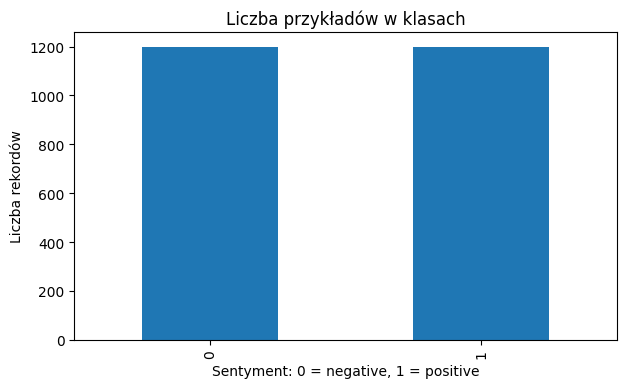

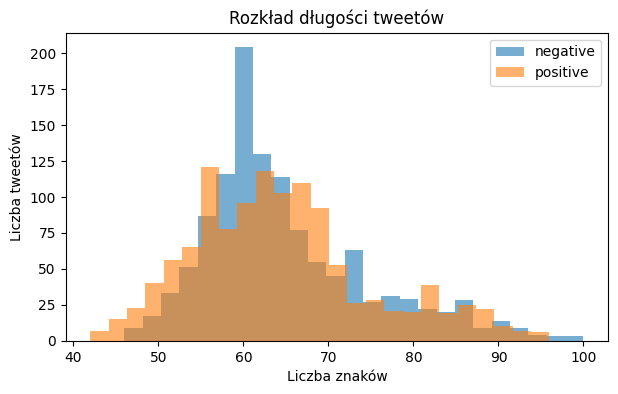

In [3]:
# 3. Szybka analiza danych
data["char_len"] = data["text"].str.len()

fig, ax = plt.subplots(figsize=(7, 4))
data["sentiment"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Liczba przykładów w klasach")
ax.set_xlabel("Sentyment: 0 = negative, 1 = positive")
ax.set_ylabel("Liczba rekordów")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(data.loc[data.sentiment == 0, "char_len"], bins=25, alpha=0.6, label="negative")
ax.hist(data.loc[data.sentiment == 1, "char_len"], bins=25, alpha=0.6, label="positive")
ax.set_title("Rozkład długości tweetów")
ax.set_xlabel("Liczba znaków")
ax.set_ylabel("Liczba tweetów")
ax.legend()
plt.show()


## 3. Czyszczenie tekstu

Nie usuwamy wszystkiego agresywnie. W analizie sentymentu znaki takie jak `!`, emotikony, hashtagi czy negacja mogą nieść sygnał.

Tutaj:
- URL → `<url>`
- wzmianka `@user` → `<user>`
- `#happy` → `happy`
- tekst → małe litery


In [4]:
# 4. Czyszczenie i tokenizacja
def clean_text(text):
    text = text.lower().strip()
    text = re.sub(r"https?://\S+|www\.\S+", " <url> ", text)
    text = re.sub(r"@\w+", " <user> ", text)
    text = re.sub(r"#(\w+)", r" \1 ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

TOKEN_RE = re.compile(r"<url>|<user>|[a-z]+(?:'[a-z]+)?|[:;][()]+|[!?]+")

def tokenize(text):
    return TOKEN_RE.findall(clean_text(text))

data["clean_text"] = data["text"].map(clean_text)
data[["sentiment", "text", "clean_text"]].head()


,sentiment,text,clean_text
0,1,"I pretty love this interface, it is fantastic ...","i pretty love this interface, it is fantastic ..."
1,0,"@shop please fix this, the website is frustrat...","<user> please fix this, the website is frustra..."
2,0,The new camera is annoying; I would regret it ...,the new camera is annoying; i would regret it ...
3,1,The new design is beautiful; I would enjoy it ...,the new design is beautiful; i would enjoy it ...
4,1,The new design is brilliant; I would appreciat...,the new design is brilliant; i would appreciat...


In [5]:
# 5. Podział train / validation / test: 70% / 15% / 15%
train_df, temp_df = train_test_split(
    data, test_size=0.30, random_state=SEED, stratify=data["sentiment"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["sentiment"]
)

print("train:", len(train_df))
print("val:  ", len(val_df))
print("test: ", len(test_df))


train: 1680
val:   360
test:  360


## 4. Słownik i kodowanie

Słownik budujemy **wyłącznie na zbiorze treningowym**. To ważne, bo inaczej przemycamy informację z walidacji/testu do treningu.

`<PAD>` uzupełnia krótsze sekwencje, a `<UNK>` reprezentuje słowa spoza słownika.


In [6]:
# 6. Budowa słownika
MAX_VOCAB = 5000
MAX_LEN = 32

counter = Counter()
for text in train_df["clean_text"]:
    counter.update(tokenize(text))

itos = ["<PAD>", "<UNK>"] + [w for w, _ in counter.most_common(MAX_VOCAB - 2)]
stoi = {word: idx for idx, word in enumerate(itos)}

PAD_IDX = stoi["<PAD>"]
UNK_IDX = stoi["<UNK>"]

print("Rozmiar słownika:", len(itos))
print("Najczęstsze tokeny:", counter.most_common(20))

def encode(text, max_len=MAX_LEN):
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)]
    ids = ids[:max_len]
    length = max(1, len(ids))
    ids = ids + [PAD_IDX] * (max_len - len(ids))
    return ids, length


Rozmiar słownika: 101
Najczęstsze tokeny: [('it', 1146), ('is', 991), ('this', 983), ('the', 839), ('i', 577), ('with', 569), ('<url>', 318), ('new', 289), ('would', 289), ('by', 278), ('everything', 278), ('feels', 278), ('what', 275), ('a', 275), ('!', 275), ('<user>', 256), ('disappointed', 253), ('happy', 245), ('so', 225), ('bad', 217)]


In [7]:
# 7. Dataset i DataLoader
class TweetDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["clean_text"].tolist()
        self.labels = frame["sentiment"].astype(np.float32).tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids, length = encode(self.texts[idx])
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32),
        )

BATCH_SIZE = 64

train_loader = DataLoader(TweetDataset(train_df), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TweetDataset(val_df), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TweetDataset(test_df), batch_size=BATCH_SIZE, shuffle=False)

x, lengths, y = next(iter(train_loader))
print("x:", x.shape, "lengths:", lengths.shape, "y:", y.shape)


x: torch.Size([64, 32]) lengths: torch.Size([64]) y: torch.Size([64])


## 5. Model wspólny dla RNN, LSTM i GRU

To samo wejście przechodzi przez:
1. `Embedding`,
2. wybraną warstwę rekurencyjną,
3. `Dropout`,
4. klasyfikator liniowy.

Używamy `pack_padded_sequence`, żeby model ignorował techniczne dopełnienie `<PAD>`.


In [8]:
# 8. Model
class SentimentRNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        rnn_type="LSTM",
        embed_dim=64,
        hidden_dim=64,
        num_layers=1,
        dropout=0.30,
        bidirectional=False,
    ):
        super().__init__()
        self.rnn_type = rnn_type.upper()
        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)

        rnn_dropout = dropout if num_layers > 1 else 0.0
        common = dict(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=rnn_dropout,
            bidirectional=bidirectional,
        )

        if self.rnn_type == "RNN":
            self.rnn = nn.RNN(nonlinearity="tanh", **common)
        elif self.rnn_type == "LSTM":
            self.rnn = nn.LSTM(**common)
        elif self.rnn_type == "GRU":
            self.rnn = nn.GRU(**common)
        else:
            raise ValueError("rnn_type musi być jednym z: RNN, LSTM, GRU")

        directions = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * directions, 1)

    def forward(self, x, lengths):
        emb = self.embedding(x)

        packed = pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn_type == "LSTM":
            hidden = hidden[0]  # h_n z pary (h_n, c_n)

        if self.bidirectional:
            last = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            last = hidden[-1]

        logits = self.fc(self.dropout(last)).squeeze(1)
        return logits


In [9]:
# 9. Funkcje treningu i ewaluacji
def evaluate(model, loader, criterion):
    model.eval()
    losses, preds, labels = [], [], []

    with torch.no_grad():
        for x, lengths, y in loader:
            x, lengths, y = x.to(DEVICE), lengths.to(DEVICE), y.to(DEVICE)
            logits = model(x, lengths)
            loss = criterion(logits, y)

            prob = torch.sigmoid(logits)
            pred = (prob >= 0.5).long()

            losses.append(loss.item())
            preds.extend(pred.cpu().numpy().tolist())
            labels.extend(y.long().cpu().numpy().tolist())

    return np.mean(losses), accuracy_score(labels, preds)

def train_model(model, train_loader, val_loader, epochs=4, lr=2e-3):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_state = None
    best_val_loss = float("inf")

    for epoch in range(1, epochs + 1):
        model.train()
        losses, preds, labels = [], [], []

        for x, lengths, y in train_loader:
            x, lengths, y = x.to(DEVICE), lengths.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()
            logits = model(x, lengths)
            loss = criterion(logits, y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            prob = torch.sigmoid(logits)
            pred = (prob >= 0.5).long()

            losses.append(loss.item())
            preds.extend(pred.detach().cpu().numpy().tolist())
            labels.extend(y.long().cpu().numpy().tolist())

        train_loss = np.mean(losses)
        train_acc = accuracy_score(labels, preds)
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(
            f"Epoch {epoch:02d} | "
            f"train loss={train_loss:.4f}, acc={train_acc:.3f} | "
            f"val loss={val_loss:.4f}, acc={val_acc:.3f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return history


## 6. Eksperyment: SimpleRNN vs LSTM vs GRU

Poniżej trenujemy trzy modele przy **tych samych hiperparametrach**. Dzięki temu porównanie jest uczciwsze.

Na prawdziwym, dużym zbiorze różnice będą znacznie ciekawsze niż na małym zbiorze demonstracyjnym.


In [10]:
# 10. Trening trzech architektur
EPOCHS = 4
EMBED_DIM = 64
HIDDEN_DIM = 64
LEARNING_RATE = 2e-3

models = {}
histories = {}
summary_rows = []

for kind in ["RNN", "LSTM", "GRU"]:
    print("\n" + "=" * 70)
    print("MODEL:", kind)

    model = SentimentRNN(
        vocab_size=len(itos),
        rnn_type=kind,
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        dropout=0.30,
    ).to(DEVICE)

    history = train_model(
        model, train_loader, val_loader,
        epochs=EPOCHS, lr=LEARNING_RATE
    )

    val_loss, val_acc = evaluate(model, val_loader, nn.BCEWithLogitsLoss())

    models[kind] = model
    histories[kind] = history
    summary_rows.append({"model": kind, "val_loss": val_loss, "val_accuracy": val_acc})

results = pd.DataFrame(summary_rows).sort_values("val_loss").reset_index(drop=True)
results



MODEL: RNN


Epoch 01 | train loss=0.3839, acc=0.857 | val loss=0.0880, acc=0.983
Epoch 02 | train loss=0.0233, acc=0.998 | val loss=0.0043, acc=1.000


Epoch 03 | train loss=0.0036, acc=1.000 | val loss=0.0021, acc=1.000


Epoch 04 | train loss=0.0019, acc=1.000 | val loss=0.0012, acc=1.000

MODEL: LSTM


Epoch 01 | train loss=0.4789, acc=0.868 | val loss=0.1727, acc=0.983


...

Epoch 01 | train loss=0.3993, acc=0.880 | val loss=0.1252, acc=0.986


Epoch 02 | train loss=0.0381, acc=0.995 | val loss=0.0048, acc=1.000


Epoch 03 | train loss=0.0033, acc=1.000 | val loss=0.0019, acc=1.000


Epoch 04 | train loss=0.0016, acc=1.000 | val loss=0.0010, acc=1.000


,model,val_loss,val_accuracy
0,GRU,0.001028,1.0
1,RNN,0.001170,1.0
2,LSTM,0.001344,1.0


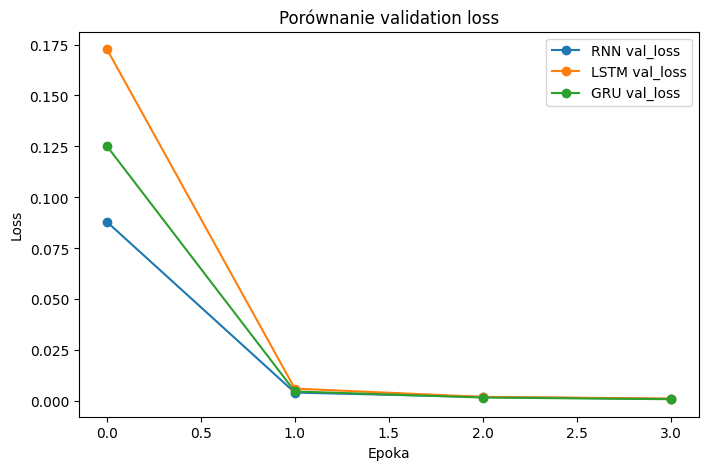

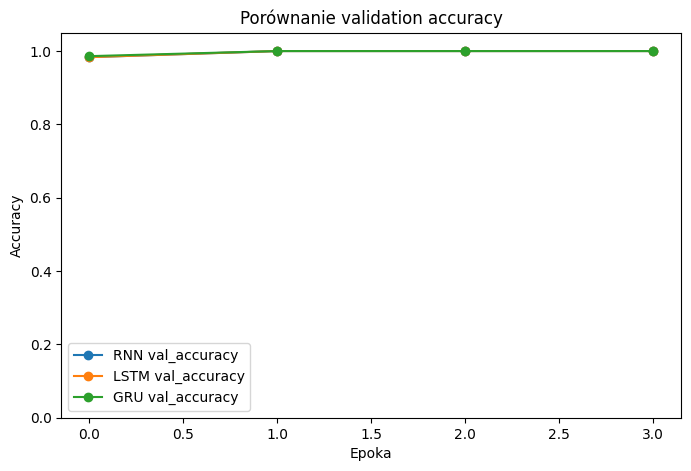

In [11]:
# 11. Krzywe treningu
fig, ax = plt.subplots(figsize=(8, 5))
for kind, h in histories.items():
    ax.plot(h["val_loss"], marker="o", label=f"{kind} val_loss")
ax.set_title("Porównanie validation loss")
ax.set_xlabel("Epoka")
ax.set_ylabel("Loss")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for kind, h in histories.items():
    ax.plot(h["val_acc"], marker="o", label=f"{kind} val_accuracy")
ax.set_title("Porównanie validation accuracy")
ax.set_xlabel("Epoka")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()


## 7. Test najlepszego modelu

Model wybieramy na podstawie **validation loss**, a dopiero potem raz oceniamy na zbiorze testowym.
To chroni przed ręcznym dostrajaniem do testu.


In [12]:
# 12. Test najlepszego modelu
best_kind = results.iloc[0]["model"]
best_model = models[best_kind]

print("Najlepszy model wg val_loss:", best_kind)

criterion = nn.BCEWithLogitsLoss()
test_loss, test_acc = evaluate(best_model, test_loader, criterion)

all_probs, all_preds, all_labels = [], [], []
best_model.eval()

with torch.no_grad():
    for x, lengths, y in test_loader:
        x, lengths = x.to(DEVICE), lengths.to(DEVICE)
        logits = best_model(x, lengths)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).long()

        all_probs.extend(probs.cpu().numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
        all_labels.extend(y.long().numpy().tolist())

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=["negative", "positive"], digits=4))


Najlepszy model wg val_loss: GRU
Test loss:     0.0010
Test accuracy: 1.0000

              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000       180
    positive     1.0000    1.0000    1.0000       180

    accuracy                         1.0000       360
   macro avg     1.0000    1.0000    1.0000       360
weighted avg     1.0000    1.0000    1.0000       360



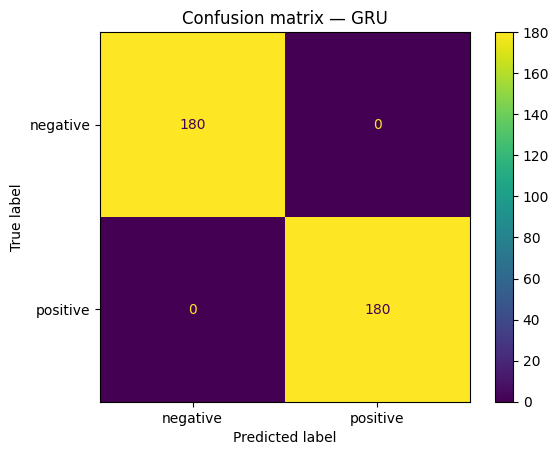

In [13]:
# 13. Macierz pomyłek
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"])
disp.plot(values_format="d")
plt.title(f"Confusion matrix — {best_kind}")
plt.show()


## 8. Predykcja własnego tekstu

Funkcja zwraca:
- klasę,
- prawdopodobieństwo pozytywnego sentymentu.

Warto testować zdania proste i trudniejsze, np. z negacją albo ironią. Takie przykłady szybko pokazują ograniczenia małego modelu rekurencyjnego.


In [14]:
# 14. Predykcja nowych zdań
def predict_sentiment(text, model=best_model):
    ids, length = encode(clean_text(text))
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)
    lengths = torch.tensor([length], dtype=torch.long, device=DEVICE)

    model.eval()
    with torch.no_grad():
        logit = model(x, lengths)
        prob_positive = torch.sigmoid(logit).item()

    label = "positive" if prob_positive >= 0.5 else "negative"
    return {
        "text": text,
        "label": label,
        "p_positive": round(prob_positive, 4),
        "p_negative": round(1 - prob_positive, 4),
    }

examples = [
    "I love this product! It works perfectly.",
    "This update is awful and completely broken.",
    "Not bad at all, I actually like it.",
    "Great, another crash... exactly what I needed.",
    "@support the new camera is fantastic! #happy",
]

pd.DataFrame([predict_sentiment(t) for t in examples])


,text,label,p_positive,p_negative
0,I love this product! It works perfectly.,positive,0.9862,0.0138
1,This update is awful and completely broken.,negative,0.0012,0.9988
2,"Not bad at all, I actually like it.",positive,0.9532,0.0468
3,"Great, another crash... exactly what I needed.",positive,0.9962,0.0038
4,@support the new camera is fantastic! #happy,positive,0.9942,0.0058


## 9. Co mają optymalizować kursanci?

### Poziom 1 — hiperparametry
Spróbuj zmienić:
- `EMBED_DIM`: 32, 64, 128,
- `HIDDEN_DIM`: 32, 64, 128,
- `BATCH_SIZE`: 32, 64, 128,
- `LEARNING_RATE`: `1e-3`, `2e-3`, `5e-4`,
- `MAX_LEN`: 16, 32, 64.

### Poziom 2 — architektura
1. `num_layers=2`
2. `bidirectional=True`
3. większy lub mniejszy dropout
4. GRU zamiast LSTM albo odwrotnie

### Poziom 3 — dane
1. użyj pełnego Sentiment140,
2. sprawdź balans klas,
3. popraw preprocessing,
4. usuń duplikaty,
5. przeanalizuj najczęstsze błędy.

### Poziom 4 — analiza jakości
Nie pytaj tylko: **„ile accuracy?”**  
Zapytaj:
- gdzie model się myli?
- czy radzi sobie z negacją?
- czy radzi sobie z ironią?
- czy emotikony dominują nad słowami?
- jak zachowuje się dla słów spoza słownika?
- czy RNN traci informację w dłuższych sekwencjach?


## 9. Stress test: negacja, ironia i mieszany sentyment

To **nie jest część zbioru testowego**. To ręcznie przygotowany mały zestaw OOD (out-of-distribution), który sprawdza, czy model rozumie coś więcej niż pojedyncze słowa-klucze.

Właśnie tutaj często wychodzą ograniczenia prostych modeli i zbyt łatwych danych treningowych.


In [15]:
# 15. Stress test
hard_examples = pd.DataFrame([
    (0, "I do not love this app at all."),
    (1, "This is not bad, actually it works quite well."),
    (0, "Great, it crashed again. Exactly what I needed."),
    (1, "I expected it to be terrible, but it is fantastic."),
    (0, "The design is beautiful but the service is awful."),
    (1, "The delivery was slow, yet the product is excellent."),
    (0, "I used to love this app before the broken update."),
    (1, "I hate waiting, but the support team solved everything."),
], columns=["expected", "text"])

hard_pred = pd.DataFrame([predict_sentiment(t) for t in hard_examples["text"]])
hard_result = pd.concat(
    [hard_examples.reset_index(drop=True), hard_pred[["label", "p_positive"]]],
    axis=1
)
hard_result["predicted"] = (hard_result["label"] == "positive").astype(int)
hard_result["correct"] = hard_result["predicted"] == hard_result["expected"]

print("Stress-test accuracy:", round(hard_result["correct"].mean(), 3))
hard_result


Stress-test accuracy: 0.5


,expected,text,label,p_positive,predicted,correct
0,0,I do not love this app at all.,positive,0.9970,1,False
1,1,"This is not bad, actually it works quite well.",positive,0.9341,1,True
2,0,"Great, it crashed again. Exactly what I needed.",positive,0.9963,1,False
3,1,"I expected it to be terrible, but it is fantas...",positive,0.9963,1,True
4,0,The design is beautiful but the service is awful.,positive,0.9739,1,False
5,1,"The delivery was slow, yet the product is exce...",positive,0.9937,1,True
6,0,I used to love this app before the broken update.,positive,0.9954,1,False
7,1,"I hate waiting, but the support team solved ev...",positive,0.9964,1,True


In [16]:
# 16. Zapis najlepszego modelu
MODEL_FILE = f"best_{best_kind.lower()}_sentiment.pt"

torch.save({
    "model_type": best_kind,
    "model_state_dict": best_model.state_dict(),
    "stoi": stoi,
    "itos": itos,
    "max_len": MAX_LEN,
    "embed_dim": EMBED_DIM,
    "hidden_dim": HIDDEN_DIM,
}, MODEL_FILE)

print("Zapisano:", MODEL_FILE)


Zapisano: best_gru_sentiment.pt


## 10. Wnioski do omówienia na zajęciach

- **RNN** jest najprostszą architekturą rekurencyjną, ale może mieć problem z długimi zależnościami i zanikającym gradientem.
- **LSTM** dodaje pamięć komórki i bramki sterujące przepływem informacji.
- **GRU** upraszcza mechanizm bramek względem LSTM i często daje podobną jakość przy mniejszej liczbie parametrów.
- Wynik na małym zbiorze demonstracyjnym nie mówi wiele o jakości modelu produkcyjnego.
- Prawdziwym testem są dane spoza rozkładu treningowego: ironia, negacja, slang, literówki, nowe hashtagi, wieloznaczność.

**Dalszy krok:** porównaj wynik z transformerem (np. DistilBERT) i zapytaj, kiedy prostszy RNN nadal ma sens.
